# HRP allocator backtested

Run the HRP allocator through the engine pipeline

Expectations:

- HRP’s capped weights may behave closer to a capped low-volatility portfolio than to a clustering-driven one
- Volatility and drawdown: should lie between min var and risk weighted, as per the sanity check
- Turnover: the book states that HRP is more stable than optimziers, so should be lower than min var. The tree however can reorder every month and with cap it will redistribute excesses differently each time
- Sharpe: the book claims it yields better out of sample risk but there is no mention of risk adjusted returns

In [2]:
# Imports

import pandas as pd
import tabulate
from vportfolio import load_data, pipelines, allocators, plotting, trials
from vportfolio.params import TRIALS_LOG, BACKTEST, ROOT
import matplotlib.pyplot as plt

In [4]:
# load data

data = load_data.load_universe()

In [7]:
# run the allocator through the engine

row_hrp = pipelines.trial_pipeline("hrp", allocators.hrp, "candidate", data)

In [8]:
# compare with all logged strategies
log = pd.read_csv(TRIALS_LOG).set_index("name")
log[["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]].round(3)

,role,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover
name,,,,,,
sixty_forty,benchmark,0.082,0.114,0.650,-0.357,0.022
equal_weights,benchmark,0.057,0.100,0.492,-0.337,0.038
risk_weighted,diagnostic,0.042,0.052,0.588,-0.194,0.035
min_var_raw,candidate,0.026,0.034,0.438,-0.141,0.070
min_var_denoised,candidate,0.027,0.034,0.469,-0.140,0.068
hrp,candidate,0.031,0.038,0.532,-0.117,0.122


The turnover of the hrp model is very high compared to the others. It seems that the structure of the model is working against itself. 
- The tree reorders every month. Single linkage is sensitive: a small change in one correlation can move an ETF to a different branch, which changes the leaf order.
- Bisection is by count, not by branch. When the order shifts, an ETF can land in a different half at the top split, and its weight is multiplied by a very different α. A tiny change in the data becomes a large jump in weight.
- The cap amplifies it: about 70% of the portfolio gets redistributed every month, in proportions that follow these unstable small weights.

In essence, HRP's stability claim works well for the covariance, but not for the ordering in this universe and with this cap restriction.

Before moving on, I want to check how correlated the performance of hrp is to risk weighted and min var denoised

In [9]:
r = {n: pd.read_parquet(BACKTEST / f"{n}_returns.parquet")[n] for n in ["hrp", "risk_weighted", "min_var_denoised"]}
pd.DataFrame(r).corr().round(2)

,hrp,risk_weighted,min_var_denoised
hrp,1.00,0.73,0.88
risk_weighted,0.73,1.00,0.79
min_var_denoised,0.88,0.79,1.00


**Result**: HRP's daily returns correlate 0.88 with minimum variance and 0.73
with risk-weighted, and its volatility (3.8%) is close to minimum variance's (3.4%).
The clustering still shapes the portfolio, which concentrates in the risk-off branch of
the tree, and causes its instability: the monthly reordering of the single-linkage tree
drives the highest turnover of all strategies (12.2% per rebalance).

In [10]:
# print the results in a format that I can copy in markdown files
print(log[["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]].round(3).to_markdown())

| name             | role       |   ann_return |   ann_vol |   sharpe |   max_drawdown |   avg_turnover |
|:-----------------|:-----------|-------------:|----------:|---------:|---------------:|---------------:|
| sixty_forty      | benchmark  |        0.082 |     0.114 |    0.65  |         -0.357 |          0.022 |
| equal_weights    | benchmark  |        0.057 |     0.1   |    0.492 |         -0.337 |          0.038 |
| risk_weighted    | diagnostic |        0.042 |     0.052 |    0.588 |         -0.194 |          0.035 |
| min_var_raw      | candidate  |        0.026 |     0.034 |    0.438 |         -0.141 |          0.07  |
| min_var_denoised | candidate  |        0.027 |     0.034 |    0.469 |         -0.14  |          0.068 |
| hrp              | candidate  |        0.031 |     0.038 |    0.532 |         -0.117 |          0.122 |


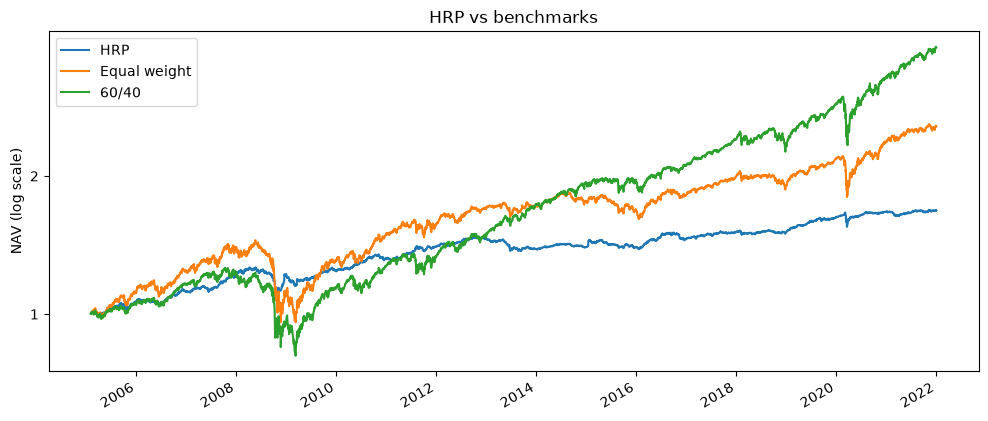

In [4]:
# let's visualize the performance of minimum hrp vs benchmark allocators

allocators_nav = trials.load_navs(["hrp", "min_var_denoised", "equal_weights", "sixty_forty"])

chart2 = allocators_nav[["hrp", "equal_weights", "sixty_forty"]].rename(columns={
    "hrp": "HRP",
    "equal_weights": "Equal weight",
    "sixty_forty": "60/40"})

ax = chart2.plot(logy=True, figsize=(12, 5), title="HRP vs benchmarks")
plotting.format_log_axis(ax)
ax.minorticks_off()
ax.set_ylabel("NAV (log scale)")
ax.set_xlabel("")
plt.show()

In [7]:
# let's save the picture to add it to the  markdown file
ax.figure.savefig(ROOT / "docs" / "figures" / "hrp.png", dpi=150, bbox_inches="tight")
plt.show()

The results are fvery similar to the minimum variance allocator, which is consistent with the correlation analysis